# Bab 5 - Mempelajari Banyak Bobot Sekaligus: Memperumum Gradient Descent

**Buku:** *Grokking Deep Learning* (Andrew W. Trask, Manning)

## Ringkasan bab
Jaringan dunia nyata memiliki banyak bobot. Bab ini memperumum gradient descent dari satu bobot ke banyak bobot:

1. **Gradient descent dengan banyak input** - satu `delta` untuk node output; setiap bobot mendapatkan `weight_delta[i] = input[i] * delta`.
2. **Membekukan (freezing) satu bobot** - untuk melihat bagaimana bobot saling berinteraksi, biarkan satu bobot tetap konstan sementara bobot lainnya belajar. Error tetap mencapai nol, karena jaringan dapat mengompensasi dengan bobot lainnya.
3. **Gradient descent dengan banyak output** - setiap output memiliki delta tersendiri, dan input tunggal digunakan bersama (*shared*).
4. **Gradient descent dengan banyak input *dan* output** - pembaruan bobot menjadi **outer product** dari vektor input dan vektor delta.
5. **Visualisasi pembaruan bobot** - bagaimana hubungan bobot dengan data tempat mereka belajar.

## Teori secara mendalam

### Beberapa input, satu output
`pred = sum(input_i * weight_i)`; `delta = pred - goal`; `error = delta^2`. Karena prediksi berupa penjumlahan, error merespons setiap bobot
*secara independen dan linear*: `d error / d weight_i = 2 * delta * input_i`. Jadi setiap bobot diperbarui sebesar `alpha * delta * input_i`:
bobot yang terhubung ke input yang **lebih besar** berubah lebih banyak, dan bobot yang terhubung ke input 0 tidak berubah sama sekali.

### Mengapa membekukan bobot tetap bekerja
Permukaan error adalah mangkuk dalam banyak dimensi. Membekukan satu bobot hanya membatasi pergerakan pada satu irisan dari mangkuk tersebut; titik terendah dari irisan tersebut masih
dapat dicapai, sehingga error tetap mencapai nol - bobot lainnya belajar mengambil alih tugas bobot yang dibekukan. Ini menunjukkan bahwa jaringan hanya berusaha mengurangi
error total dan tidak "tahu" bobot mana yang "seharusnya" penting.

### Beberapa output
Dengan banyak output, setiap node output membuat prediksinya sendiri, menghitung `delta`-nya sendiri, dan memperbarui bobotnya *sendiri* dari input bersama. Setiap output belajar secara independen satu sama lain.

### Banyak input dan output
`weight_deltas = outer(input, delta)` : `weight_delta[i][j] = input[i] * delta[j]`. Setiap bobot menghubungkan tepat satu input ke satu output, sehingga pembaruannya hanya menggunakan kedua angka tersebut.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Gradient descent dengan banyak input
Data yang sama seperti Bab 3 (jari kaki, rekor menang/kalah, jumlah penggemar), target = 1 (tim menang).

In [2]:
toes   = np.array([8.5, 9.5, 9.9, 9.0])
wlrec  = np.array([0.65, 0.8, 0.8, 0.9])
nfans  = np.array([1.2, 1.3, 0.5, 1.0])
win_or_lose_binary = np.array([1, 1, 0, 1])

weights = np.array([0.1, 0.2, -0.1])
alpha = 0.01
inp = np.array([toes[0], wlrec[0], nfans[0]])
true = win_or_lose_binary[0]

for it in range(40):
    pred = inp.dot(weights)
    error = (pred - true) ** 2
    delta = pred - true
    weight_deltas = inp * delta
    weights = weights - alpha * weight_deltas
    if it % 8 == 0 or it == 39:
        print(f'iter {it:2d}  pred={pred:.4f}  error={error:.5f}  weights={np.round(weights, 4)}')

iter  0  pred=0.8600  error=0.01960  weights=[ 0.1119  0.2009 -0.0983]
iter  8  pred=1.0000  error=0.00000  weights=[ 0.1161  0.2012 -0.0977]
iter 16  pred=1.0000  error=0.00000  weights=[ 0.1161  0.2012 -0.0977]
iter 24  pred=1.0000  error=0.00000  weights=[ 0.1161  0.2012 -0.0977]
iter 32  pred=1.0000  error=0.00000  weights=[ 0.1161  0.2012 -0.0977]
iter 39  pred=1.0000  error=0.00000  weights=[ 0.1161  0.2012 -0.0977]


Bobot pada `toes` (input terbesar, 8.5) bergerak paling banyak dan bobot pada `wlrec` (input terkecil) bergerak paling sedikit, persis seperti yang diprediksikan oleh `weight_delta = input * delta`.

## 2. Membekukan (freezing) satu bobot

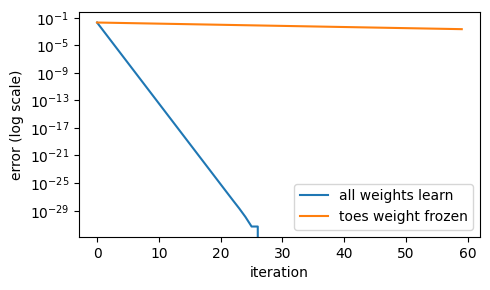

final weights (all learn): [ 0.116  0.201 -0.098]
final weights (frozen):    [ 0.1    0.233 -0.039]


In [3]:
def train_multi(freeze_first=False, iterations=60, alpha=0.01):
    weights = np.array([0.1, 0.2, -0.1])
    inp = np.array([toes[0], wlrec[0], nfans[0]])
    true = win_or_lose_binary[0]
    errs = []
    for _ in range(iterations):
        pred = inp.dot(weights)
        delta = pred - true
        errs.append(delta ** 2)
        weight_deltas = inp * delta
        if freeze_first:
            weight_deltas[0] = 0           # weight 0 is frozen
        weights -= alpha * weight_deltas
    return errs, weights

e_all, w_all = train_multi(False)
e_frz, w_frz = train_multi(True)
plt.figure(figsize=(5, 3))
plt.plot(e_all, label='all weights learn'); plt.plot(e_frz, label='toes weight frozen')
plt.yscale('log'); plt.xlabel('iteration'); plt.ylabel('error (log scale)'); plt.legend()
plt.tight_layout(); plt.show()
print('final weights (all learn):', np.round(w_all, 3))
print('final weights (frozen):   ', np.round(w_frz, 3))

Kedua iterasi mencapai error mendekati nol. Ketika bobot pertama dibekukan, dua bobot lainnya bergerak lebih jauh untuk mengompensasinya (bandingkan bobot akhir di atas), menunjukkan bahwa banyak konfigurasi bobot yang berbeda dapat memberikan prediksi yang sama.

## 3. Gradient descent dengan banyak output
Satu input (rekor menang/kalah), tiga output (cedera/hurt, menang/win, sedih/sad).

In [4]:
weights = np.array([0.3, 0.2, 0.9])
inp = wlrec[0]
true = np.array([0.1, 1.0, 0.1])
alpha = 0.1

for it in range(60):
    pred = inp * weights
    delta = pred - true
    weight_deltas = delta * inp
    weights = weights - alpha * weight_deltas
print('final predictions:', np.round(inp * weights, 3), ' targets:', true)

final predictions: [0.107 0.935 0.136]  targets: [0.1 1.  0.1]


## 4. Banyak input dan banyak output

In [5]:
#            toes  %win  #fans
weights = np.array([[0.1, 0.1, -0.3],
                    [0.1, 0.2,  0.0],
                    [0.0, 1.3,  0.1]])

hurt = np.array([0.1, 0.0, 0.0, 0.1])
win  = np.array([1, 1, 0, 1])
sad  = np.array([0.1, 0.0, 0.1, 0.2])
alpha = 0.01

inp = np.array([toes[0], wlrec[0], nfans[0]])
true = np.array([hurt[0], win[0], sad[0]])

for it in range(200):
    pred = weights.dot(inp)
    delta = pred - true
    weight_deltas = np.outer(delta, inp)       # outer product: one update per weight
    weights = weights - alpha * weight_deltas
    if it in (0, 50, 199):
        print(f'iter {it:3d}  error per output = {np.round(delta ** 2, 5)}')
print('final predictions:', np.round(weights.dot(inp), 3), ' targets:', true)

iter   0  error per output = [2.0703e-01 4.0000e-04 7.4823e-01]
iter  50  error per output = [0. 0. 0.]
iter 199  error per output = [0. 0. 0.]
final predictions: [0.1 1.  0.1]  targets: [0.1 1.  0.1]


## 5. Apa makna dari bobot?
Setelah melatih pada **banyak** contoh, bobot setiap input mencerminkan bagaimana input tersebut berhubungan dengan output yang diberinya makan. Kita dapat melihat ini dalam kasus kecil:
belajar dari keempat baris (bukan hanya satu) dan bandingkan setiap bobot yang dipelajari dengan korelasi antara input tersebut dan target.

In [6]:
X = np.stack([toes, wlrec, nfans], axis=1)
y = win_or_lose_binary.astype(float)
w = np.zeros(3)
for _ in range(5000):
    for i in range(len(X)):
        delta = X[i].dot(w) - y[i]
        w -= 0.005 * delta * X[i]
print('learned weights:  ', np.round(w, 3))
print('correlation w/ y: ', np.round([np.corrcoef(X[:, j], y)[0, 1] for j in range(3)], 3))

learned weights:   [-0.126  0.922  1.213]
correlation w/ y:  [-0.741 -0.081  0.937]


Bobot yang dipelajari adalah *kompromi* yang dipilih untuk meminimalkan error pada semua baris sekaligus. Bobot tersebut tidak identik dengan korelasi mentah: misalnya `wlrec` mendapatkan bobot yang besar meskipun korelasinya sendiri dengan target mendekati nol, karena bobot-bobot tersebut bekerja bersama dan input-input tersebut saling berkorelasi satu sama lain.
Ini memberi gambaran untuk Bab 6, di mana bobot diinterpretasikan sebagai "ringkasan korelasi (correlation summarization)".

## Poin-poin kunci
* Dengan banyak input, setiap bobot mendapatkan pembaruannya sendiri: `weight_delta_i = delta * input_i`.
* Error adalah mangkuk multi-dimensi; membekukan satu bobot tetap memungkinkan error mencapai nol.
* Dengan banyak input dan output, pembaruan membentuk outer product antara vektor delta dan vektor input.